In [ ]:
import sys,os
from glob import glob
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import IPython.display as ipd
from tqdm import tqdm
from sklearn.model_selection import train_test_split

In [55]:
crema_files = glob("speech/Crema/*/*.wav")
savee_files = glob("speech/Savee/*/*.wav")

In [56]:
len(crema_files), len(savee_files)

(7442, 480)

In [85]:
ipd.Audio(crema_files[0])

In [86]:
y, sr = librosa.load(crema_files[0])

In [87]:
y, y.shape, sr

(array([ 6.9185524e-10,  5.0900356e-10,  5.6180405e-10, ...,
        -6.0690268e-06,  2.2987717e-07,  0.0000000e+00], dtype=float32),
 (50177,),
 22050)

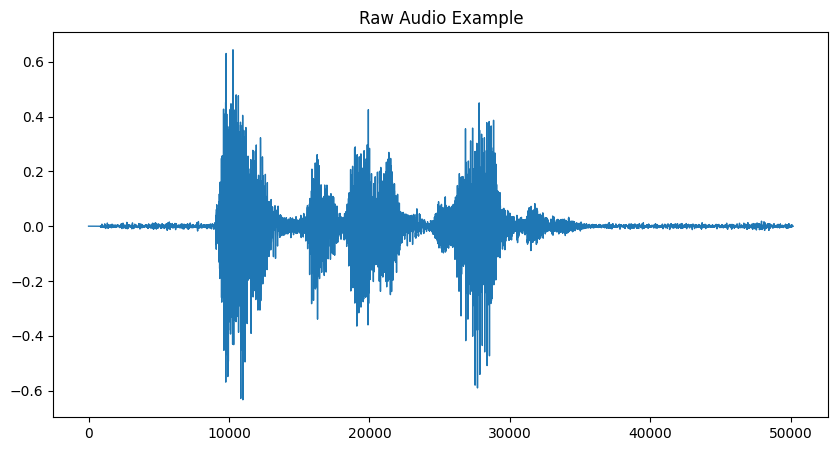

In [88]:
pd.Series(y).plot(figsize = (10, 5), lw = 1, title = "Raw Audio Example")
plt.show()

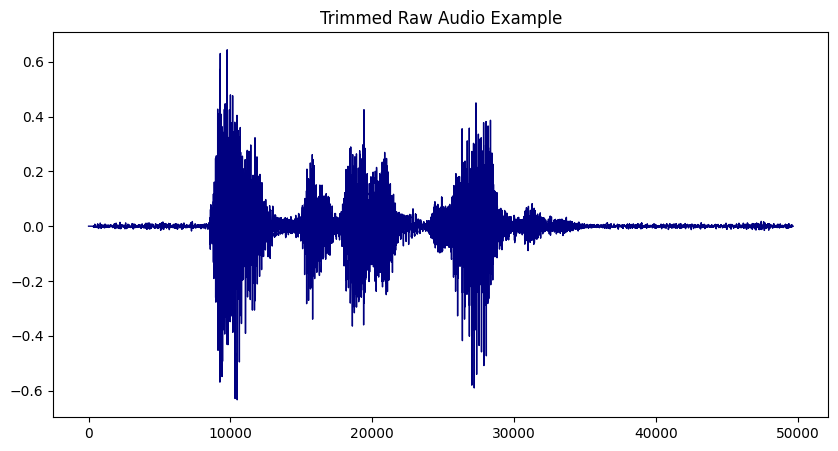

In [100]:
y_trimmed, _ = librosa.effects.trim(y, top_db = 40)
sf.write("trimmed.wav", y_trimmed, sr)
pd.Series(y_trimmed).plot(figsize = (10, 5), lw = 1, title = "Trimmed Raw Audio Example", color = "navy")
plt.show()

In [101]:
ipd.Audio("trimmed.wav")

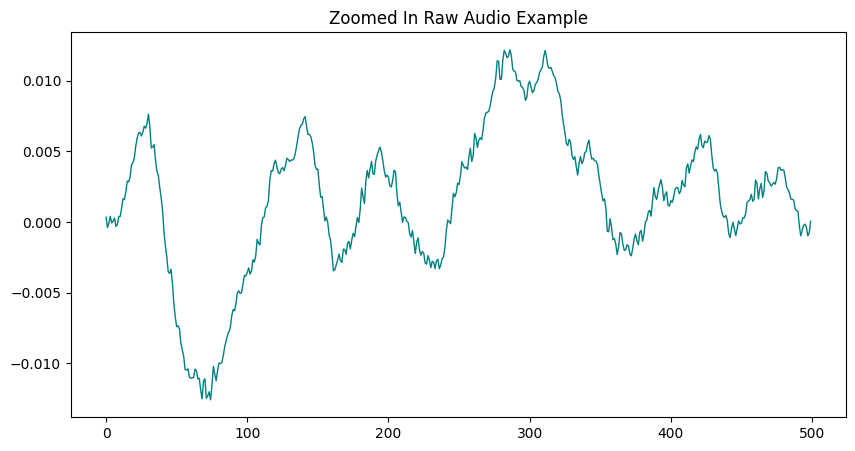

In [99]:
pd.Series(y[12000:12500]).plot(figsize = (10, 5), lw = 1, title = "Zoomed In Raw Audio Example", color = "teal")
plt.show()

In [100]:
D = librosa.stft(y)
S_db = librosa.amplitude_to_db(np.abs(D), ref = np.max)
S_db

array([[-41.407337, -33.97487 , -36.048206, ..., -42.9953  , -17.066534,
        -22.07881 ],
       [-31.541811, -29.493654, -24.996641, ..., -17.099243, -17.72814 ,
        -23.026161],
       [-25.910212, -21.350725, -20.690596, ..., -28.212667, -20.763294,
        -25.745348],
       ...,
       [-68.60127 , -74.645935, -80.      , ..., -80.      , -80.      ,
        -80.      ],
       [-68.60132 , -74.64595 , -80.      , ..., -80.      , -80.      ,
        -80.      ],
       [-68.60132 , -74.645905, -80.      , ..., -80.      , -80.      ,
        -80.      ]], dtype=float32)

In [101]:
S_db.shape

(1025, 110)

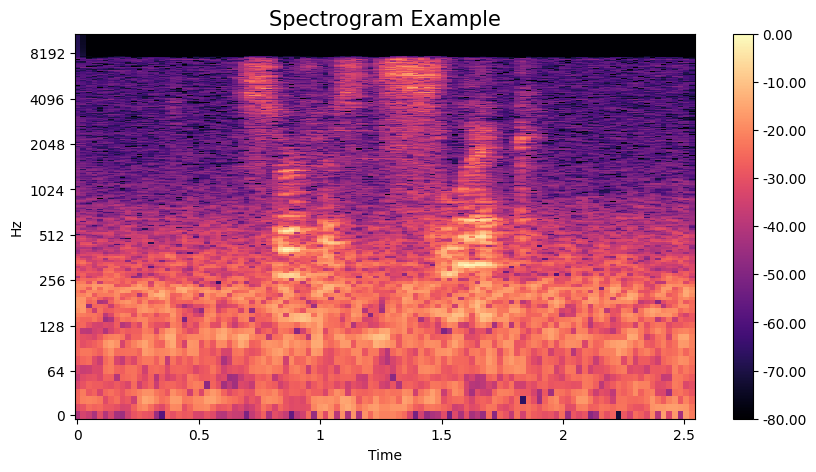

In [106]:
fig, ax = plt.subplots(figsize=(10, 5))
img = librosa.display.specshow(S_db, x_axis="time", y_axis="log", ax=ax)
ax.set_title("Spectrogram Example", fontsize=15)
fig.colorbar(img, ax=ax, format=f"%0.2f")
plt.show()

In [103]:
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=256)
S.shape

(256, 110)

In [104]:
MS_db = librosa.amplitude_to_db(np.abs(S), ref = np.max)
MS_db

array([[-55.57218 , -48.14493 , -43.965607, ..., -34.31257 , -34.24498 ,
        -44.731842],
       [-49.436375, -40.665077, -42.74852 , ..., -48.110397, -42.153996,
        -51.29021 ],
       [-55.031757, -47.1054  , -51.82319 , ..., -44.260353, -54.92307 ,
        -57.18401 ],
       ...,
       [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
        -80.      ],
       [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
        -80.      ],
       [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
        -80.      ]], dtype=float32)

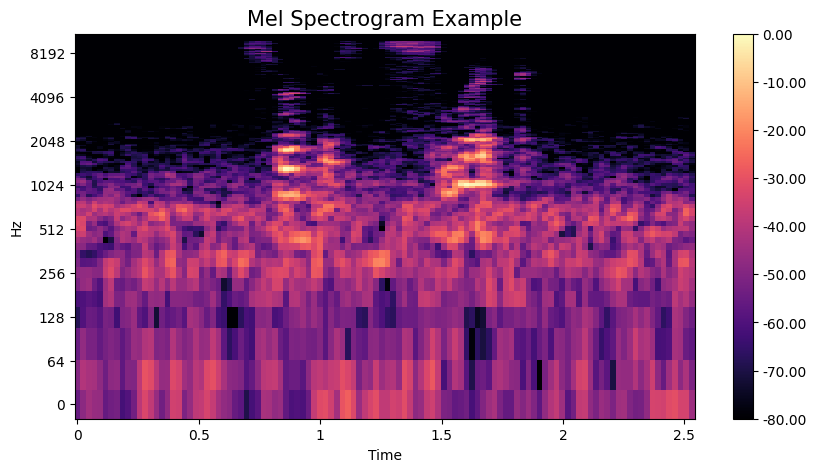

In [107]:
fig, ax = plt.subplots(figsize=(10, 5))
img_ = librosa.display.specshow(MS_db, x_axis="time", y_axis="log", ax=ax)
ax.set_title("Mel Spectrogram Example", fontsize=15)
fig.colorbar(img_, ax=ax, format=f"%0.2f")
plt.show()

Commonly used inputs are – Amplitude Envelope, Zero-Crossing Rate, Root Mean Square Energy, Spectral Centroid, Band Energy Ratio and Spectral Bandwidth.

In [16]:
import keras

In [17]:
d = keras.utils.audio_dataset_from_directory("speech/Crema", labels='inferred')

Found 7442 files belonging to 6 classes.


In [18]:
d

<_PaddedBatchDataset element_spec=(TensorSpec(shape=(None, None, None), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [40]:
#Create Metadata file
angry_crema = glob("speech/Crema/Angry/*.wav")
disgust_crema = glob("speech/Crema/Disgust/*.wav")
fear_crema = glob("speech/Crema/Fear/*.wav")
happy_crema = glob("speech/Crema/Happy/*.wav")
neutral_crema = glob("speech/Crema/Neutral/*.wav")
sad_crema = glob("speech/Crema/Sad/*.wav")
angry_savee = glob("speech/Savee/Angry/*.wav")
disgust_savee = glob("speech/Savee/Disgust/*.wav")
fear_savee = glob("speech/Savee/Fear/*.wav")
happy_savee = glob("speech/Savee/Happy/*.wav")
neutral_savee = glob("speech/Savee/Neutral/*.wav")
sad_savee = glob("speech/Savee/Sad/*.wav")

In [41]:
angry = angry_crema + angry_savee
disgust = disgust_crema + disgust_savee
fear = fear_crema + fear_savee
happy = happy_crema + happy_savee
neutral = neutral_crema + neutral_savee
sad = sad_crema + sad_savee

In [107]:
def mfccs_features(file):
    audio, sr = librosa.load(file)
    mfcc_features = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=60)
    mfcc_scaled_features = np.mean(mfcc_features.T, axis=0)
    return mfcc_scaled_features

In [14]:
extracted_mfcc = []
files = crema_files+savee_files
for i in tqdm(files):
    label = i.split("\\")[1]
    data = mfccs_features(i)
    extracted_mfcc.append([data, label])

100%|██████████████████████████████████████████████████████████████████████████████| 7922/7922 [04:37<00:00, 28.53it/s]


In [15]:
mfcc_df = pd.DataFrame(extracted_mfcc, columns=["mfcc", "class"])
mfcc_df.tail(10)

,mfcc,class
7912,"[-585.45795, 108.613266, 32.83117, 34.851738, ...",Surprise
7913,"[-551.24365, 115.00795, 12.759334, 29.953445, ...",Surprise
7914,"[-575.28705, 99.26873, 21.8803, 35.07956, -0.4...",Surprise
7915,"[-572.839, 114.169495, 27.485094, 35.286926, 1...",Surprise
7916,"[-537.40125, 132.92358, 15.153979, 17.50365, 0...",Surprise
7917,"[-580.7057, 98.990906, 28.636457, 44.699726, 7...",Surprise
7918,"[-556.7774, 120.05866, 28.79159, 36.444096, 13...",Surprise
7919,"[-585.12396, 121.73822, 38.56852, 28.324816, 9...",Surprise
7920,"[-561.785, 107.83848, 26.99788, 25.284006, 5.0...",Surprise
7921,"[-559.8409, 117.769966, 30.235182, 29.303333, ...",Surprise


In [ ]:
mfcc_df.loc[mfcc_df["class"] == "Surprise"]

In [17]:
ind = mfcc_df.loc[mfcc_df["class"] == "Surprise"].index

In [18]:
mfcc_df.drop(index=ind, axis=0, inplace=True)

In [19]:
X = np.array(mfcc_df.mfcc.tolist())
y = np.array(mfcc_df["class"].tolist())

In [20]:
X.shape

(7862, 100)

In [21]:
y.shape

(7862,)

In [22]:
y = np.array(pd.get_dummies(y))

In [23]:
y.shape

(7862, 6)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [25]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((6289, 100), (1573, 100), (6289, 6), (1573, 6))

In [26]:
#Model Building
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Input
from tensorflow.keras.optimizers import Adam
from sklearn import metrics

In [27]:
labels_num = y.shape[1]
labels_num

6

In [32]:
model = Sequential()
# layer 1
model.add(Dense(100, input_shape=(100,)))
model.add(Activation("relu"))
model.add(Dropout(0.2))
# layer 2
model.add(Dense(200))
model.add(Activation("relu"))
model.add(Dropout(0.5))
#layer 3
model.add(Dense(100))
model.add(Activation("relu"))
model.add(Dropout(0.5))
# output layer
model.add(Dense(labels_num))
model.add(Activation("softmax"))

In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 100)                 │          10,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_4 (Activation)            │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 200)                 │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_5 (Activation)            │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 100)                 │          20,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_6 (Activation)            │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 6)                   │             606 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_7 (Activation)            │ (None, 6)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 51,006 (199.24 KB)

 Trainable params: 51,006 (199.24 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(loss="categorical_crossentropy", metrics=["accuracy"], optimizer='adam')

In [ ]:
# Model Training
from tensorflow.keras.callbacks import ModelCheckpoint
from datetime import datetime

epochs = 100
batch_size = 32

checkpointer =  ModelCheckpoint(filepath="saved_models/audio_classification1.keras",
                                verbose=1, save_best_only=True)
start = datetime.now()

model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, 
          validation_data=(X_test, y_test), callbacks=checkpointer)

duration = datetime.now() - start
print("Training completed in ", duration)


In [36]:
test_accuracy = model.evaluate(X_test, y_test, verbose=0)
test_accuracy[1]

0.4259377121925354

In [62]:
# extract the pitch
def pitch_extracted(filename):
    fmin = 50 
    fmax = 500
    y, sr = librosa.load(filename)
    pitch, _, _ = librosa.pyin(y, fmin=fmin, fmax=fmax, sr=sr)
    pitch_no_nan = np.where(np.isnan(pitch), 0, pitch)
    return pitch_no_nan

def pitch_features(filename):
    p = pitch_extracted(filename)
    p = p[p > 0]
    if len(p)==0:
        features = [0]*5
    else:
        mean = np.mean(p) 
        var = np.var(p) 
        min = np.min(p) 
        max = np.max(p)
        range = max - min

        features = [mean, var, min, max, range]

    return features
    

-----------------------------------------------------------------------------------------------------------------------------------

In [235]:
df["class"].value_counts()

class
Happy      1331
Disgust    1331
Sad        1331
Angry      1331
Fear       1331
Neutral    1207
Name: count, dtype: int64

In [23]:
def plot_signal_and_augmented_signals(signal, augmented_signal, sr):
    fig, ax = plt.subplots(nrows=2)
    pd.Series(signal).plot(figsize = (10, 5), lw = 1, ax=ax[0])
    ax[0].set_title("original signal")
    pd.Series(augmented_signal).plot(figsize = (10, 5), lw = 1, ax=ax[1])
    ax[1].set_title("augmented signal")
    plt.show()

In [24]:
def add_white_noise(signal, noise_factor):
    noise = np.random.normal(0, signal.std(), signal.size)
    augmented_signal = signal + noise*noise_factor
    return augmented_signal

In [25]:
import soundfile as sf

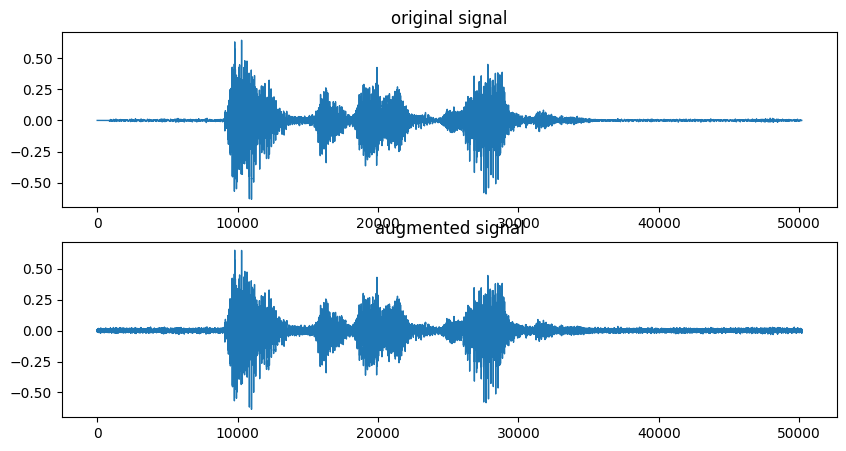

In [26]:
signal, sr = librosa.load(crema_files[0])
augmented_signal = add_white_noise(signal, 0.1)
sf.write('augmented.wav', augmented_signal, sr)
plot_signal_and_augmented_signals(signal, augmented_signal, sr)

In [30]:
ipd.Audio(crema_files[0])

In [31]:
ipd.Audio("augmented.wav")

In [46]:
def time_stretch(signal, stretch_rate):
    return librosa.effects.time_stretch(signal, rate=stretch_rate)

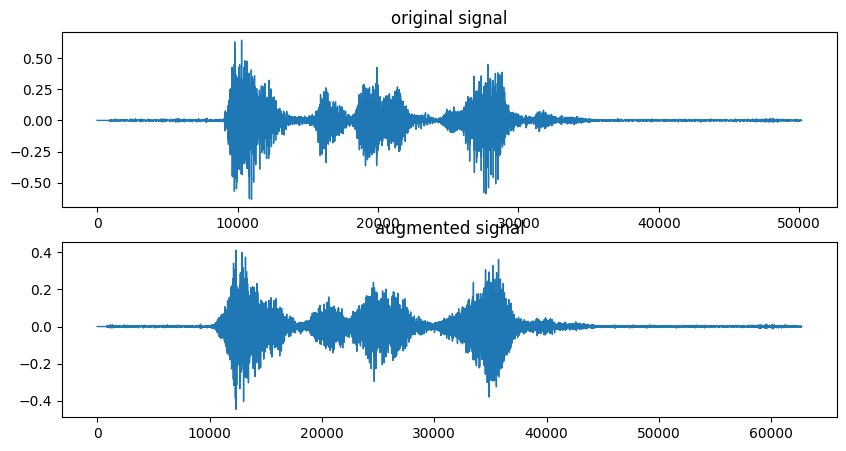

In [47]:
stretched_signal = time_stretch(signal, 0.8)
sf.write("stretched.wav", stretched_signal, sr)
plot_signal_and_augmented_signals(signal, stretched_signal, sr)

In [47]:
ipd.Audio("stretched.wav")

In [45]:
def pitch_scaling(signal, sr, num_semitones):
    return librosa.effects.pitch_shift(y=signal, sr=sr, n_steps=num_semitones)

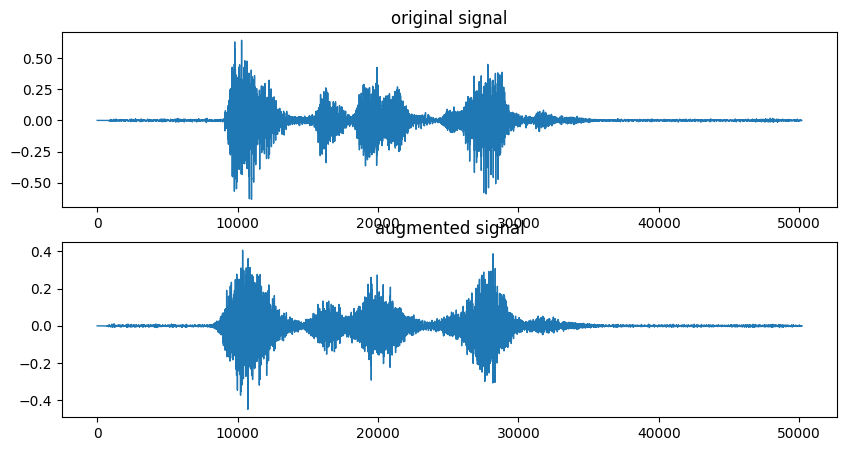

In [40]:
pitch_scaled = pitch_scaling(signal, sr, 2)
sf.write("pitch_scaled.wav", pitch_scaled, sr)
plot_signal_and_augmented_signals(signal, pitch_scaled, sr)

In [66]:
ipd.Audio("pitch_scaled.wav")

In [33]:
def random_gain(signal, min_gain_factor, max_gain_factor):
    gain_factor = np.random.uniform(min_gain_factor, max_gain_factor)
    return signal*gain_factor

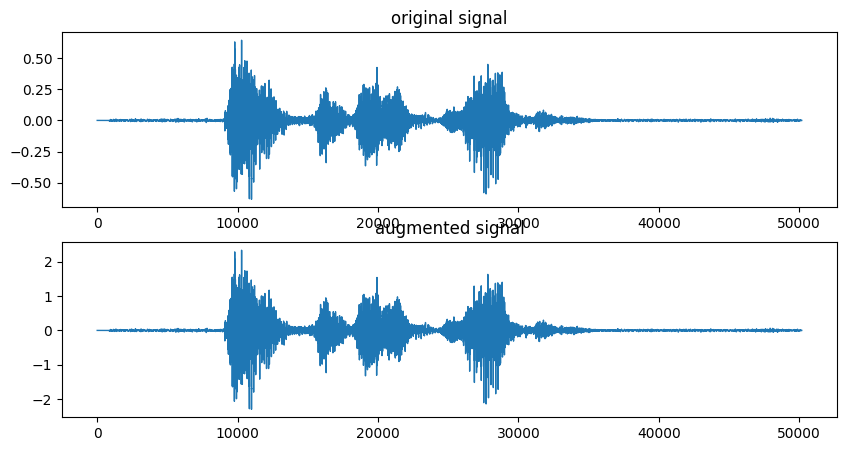

In [34]:
signal_random = random_gain(signal, 2, 4)
sf.write("random_gain.wav", signal_random, sr)
plot_signal_and_augmented_signals(signal, signal_random, sr)

In [35]:
ipd.Audio("random_gain.wav")

In [18]:
# import splitfolders
# splitfolders.ratio("speech/crema", output='crema_split', seed=1337, ratio=(.6, 0.2,0.2))

Copying files: 7448 files [01:13, 100.96 files/s]


In [19]:
# splitfolders.ratio("speech/savee", output='savee_split', seed=1337, ratio=(.6, 0.2,0.2))

Copying files: 486 files [00:05, 85.01 files/s]


In [36]:
train_c_ang = glob("crema_split/train/Angry/*.wav")
train_c_sad = glob("crema_split/train/Sad/*.wav")
train_c_ha =  glob("crema_split/train/Happy/*.wav")
train_c_neu = glob("crema_split/train/Neutral/*.wav")
train_c_fear = glob("crema_split/train/Fear/*.wav")
train_c_dis = glob("crema_split/train/Disgust/*.wav")

In [43]:
train_c_ang[1].split("\\")[1]

'1001_IEO_ANG_MD.wav'

In [48]:
# for file in tqdm(train_c_ang):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("crema_split/train/Angry/"+'aug1'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("crema_split/train/Angry/"+'aug2'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("crema_split/train/Angry"+'aug3'+file.split("\\")[1], aug3, sr)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 762/762 [00:51<00:00, 14.78it/s]


In [49]:
# for file in tqdm(train_c_sad):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("crema_split/train/Sad/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("crema_split/train/Sad/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("crema_split/train/Sad/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 762/762 [00:51<00:00, 14.68it/s]


In [50]:
# for file in tqdm(train_c_ha):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("crema_split/train/Happy/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("crema_split/train/Happy/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("crema_split/train/Happy/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 762/762 [00:47<00:00, 15.88it/s]


In [51]:
# for file in tqdm(train_c_neu):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("crema_split/train/Neutral/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("crema_split/train/Neutral/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("crema_split/train/Neutral/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 651/651 [00:40<00:00, 16.01it/s]


In [52]:
# for file in tqdm(train_c_fear):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("crema_split/train/Fear/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("crema_split/train/Fear/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("crema_split/train/Fear/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 762/762 [00:48<00:00, 15.59it/s]


In [53]:
# for file in tqdm(train_c_dis):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("crema_split/train/Disgust/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("crema_split/train/Disgust/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("crema_split/train/Disgust/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 762/762 [00:53<00:00, 14.34it/s]


In [93]:
train_s_ang = glob("savee_split/train/Angry/*.wav")
train_s_sad = glob("savee_split/train/Sad/*.wav")
train_s_ha =  glob("savee_split/train/Happy/*.wav")
train_s_neu = glob("savee_split/train/Neutral/*.wav")
train_s_fear = glob("savee_split/train/Fear/*.wav")
train_s_dis = glob("savee_split/train/Disgust/*.wav")

In [94]:
# for file in tqdm(train_s_ang):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("savee_split/train/Angry/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("savee_split/train/Angry/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("savee_split/train/Angry/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:03<00:00,  9.18it/s]


In [95]:
# for file in tqdm(train_s_sad):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("savee_split/train/Sad/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("savee_split/train/Sad/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("savee_split/train/Sad/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:04<00:00,  8.15it/s]


In [96]:
# for file in tqdm(train_s_ha):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("savee_split/train/Happy/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("savee_split/train/Happy/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("savee_split/train/Happy/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:03<00:00,  9.53it/s]


In [97]:
# for file in tqdm(train_s_fear):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("savee_split/train/Fear/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("savee_split/train/Fear/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("savee_split/train/Fear/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 35/35 [00:03<00:00,  9.36it/s]


In [98]:
# for file in tqdm(train_s_neu):
#     aud, sr = librosa.load(file)
#     aug1 = add_white_noise(aud, 0.1)
#     sf.write("savee_split/train/Neutral/"+'aug1_'+file.split("\\")[1], aug1, sr)
#     aug2 = time_stretch(aud, 0.8)
#     sf.write("savee_split/train/Neutral/"+'aug2_'+file.split("\\")[1], aug2, sr)
#     aug3 = pitch_scaling(aud, sr, 4)
#     sf.write("savee_split/train/Neutral/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 71/71 [00:07<00:00,  9.36it/s]


In [99]:
for file in tqdm(train_s_dis):
    aud, sr = librosa.load(file)
    aug1 = add_white_noise(aud, 0.1)
    sf.write("savee_split/train/Disgust/"+'aug1_'+file.split("\\")[1], aug1, sr)
    aug2 = time_stretch(aud, 0.8)
    sf.write("savee_split/train/Disgust/"+'aug2_'+file.split("\\")[1], aug2, sr)
    aug3 = pitch_scaling(aud, sr, 4)
    sf.write("savee_split/train/Disgust/"+'aug3_'+file.split("\\")[1], aug3, sr)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 36/36 [00:04<00:00,  8.53it/s]


In [102]:
def trim_audio_inplace(file_path, top_db=40):
    audio, sr = librosa.load(file_path)
    trimmed_audio, _ = librosa.effects.trim(audio, top_db=top_db)
    sf.write(file_path, trimmed_audio, sr)

In [3]:
crema_s = glob('crema_split/*/*/*.wav')
savee_s = glob('savee_split/*/*/*.wav')
files = crema_s+savee_s

In [105]:
for file in tqdm(files):
    trim_audio_inplace(file)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21986/21986 [05:15<00:00, 69.75it/s]


In [128]:
extracted_train_mfcc = []
train = glob('crema_split/train/*/*.wav')
for i in tqdm(train):
    label = i.split("\\")[1]
    data = mfccs_features(i)
    extracted_train_mfcc.append([data, label])

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17844/17844 [02:15<00:00, 131.83it/s]


In [134]:
mfcc_train_df = pd.DataFrame(extracted_train_mfcc, columns=["mfcc", "label"])
mfcc_train_df.tail(10)

,mfcc,label
17834,"[-504.11893, 121.60893, 35.315235, 25.919386, ...",Sad
17835,"[-502.62424, 122.217606, 39.867405, 38.162426,...",Sad
17836,"[-500.34, 116.20644, 34.129444, 42.579807, 4.2...",Sad
17837,"[-497.25128, 109.06822, 36.592457, 37.77498, 6...",Sad
17838,"[-497.94666, 128.8766, 30.758217, 28.765913, 8...",Sad
17839,"[-459.16998, 116.21405, 31.910534, 26.76118, -...",Sad
17840,"[-473.87915, 117.928474, 36.129147, 28.474134,...",Sad
17841,"[-457.86002, 104.49252, 27.608517, 35.35989, 3...",Sad
17842,"[-475.2181, 98.878334, 37.568474, 36.101772, 5...",Sad
17843,"[-479.67282, 111.86126, 34.407726, 28.530802, ...",Sad


In [135]:
mfcc_train_df = mfcc_train_df.sample(frac=1)
mfcc_train_df

,mfcc,label
9507,"[-381.19617, 130.34962, -1.3263983, 51.71899, ...",Happy
17347,"[-431.36438, 109.20833, 41.098026, 33.7002, -6...",Sad
9357,"[-327.87027, 134.63582, 12.231476, 45.150272, ...",Happy
17669,"[-461.553, 130.18349, 40.840572, 33.921223, -4...",Sad
2023,"[-352.63214, 125.29023, -9.735621, 40.93679, -...",Angry
...,...,...
10048,"[-241.46715, 59.292862, 13.224884, 8.171336, 5...",Happy
7058,"[-398.24078, 82.90828, 45.161026, 31.960257, 1...",Fear
3315,"[-346.26544, 120.95625, 13.11215, 23.546991, -...",Disgust
13083,"[-323.06168, 66.77551, 35.446777, 33.69732, 14...",Neutral


In [183]:
X_train = np.array(mfcc_train_df.mfcc.tolist())
y = np.array(mfcc_train_df.label.tolist())
y_train = np.array(pd.get_dummies(y))

In [170]:
X_train.shape, y_train.shape

((17844, 60), (17844, 6))

In [138]:
extracted_val_mfcc = []
val = glob('crema_split/val/*/*.wav')
for i in tqdm(val):
    label = i.split("\\")[1]
    data = mfccs_features(i)
    extracted_val_mfcc.append([data, label])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1487/1487 [00:11<00:00, 130.45it/s]


In [139]:
mfcc_val_df = pd.DataFrame(extracted_val_mfcc, columns=["mfcc", "label"])
mfcc_val_df = mfcc_val_df.sample(frac=1)
mfcc_val_df

,mfcc,label
370,"[-361.79343, 143.03813, 9.430159, 50.910275, -...",Disgust
1140,"[-365.74728, 133.4508, 10.029909, 41.109715, -...",Neutral
674,"[-427.9932, 151.06183, -0.033279832, 47.628296...",Fear
1017,"[-363.84528, 135.16397, -3.1481733, 46.681297,...",Neutral
1117,"[-413.00784, 118.966576, 21.502934, 57.697746,...",Neutral
...,...,...
288,"[-419.4056, 130.5116, 24.869358, 50.68855, -5....",Disgust
386,"[-416.05, 128.472, 22.32351, 38.381733, -8.874...",Disgust
376,"[-333.64157, 111.567245, 11.009352, 39.09897, ...",Disgust
1481,"[-510.713, 145.67326, 18.845354, 64.86833, -14...",Sad


In [184]:
X_val = np.array(mfcc_val_df.mfcc.tolist())
y_ = np.array(mfcc_val_df.label.tolist())
y_val = np.array(pd.get_dummies(y_))

In [146]:
X_val.shape, y_val.shape

((1487, 60), (1487, 6))

In [142]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

In [161]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

In [148]:
svm_model = SVC(kernel='rgb', C=1, random_state=42) 
svm_model.fit(X_train, y)

SVC(C=1, kernel='linear', random_state=42)

In [149]:
y_pred = svm_model.predict(X_val)

In [150]:
accuracy_score(y_, y_pred)

0.4001344989912576

In [151]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_val)

In [152]:
accuracy_score(y_val, y_pred_rf)

0.09952925353059852

In [190]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv1D(64, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.5),
    layers.Conv1D(128, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(6, activation='softmax')  # Output layer matches number of classes
])
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)                    │ (None, 58, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_8 (MaxPooling1D)       │ (None, 29, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 29, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_9 (Conv1D)                    │ (None, 27, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_9 (MaxPooling1D)       │ (None, 13, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 13, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 1664)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_30 (Dense)                     │ (None, 128)                 │         213,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_31 (Dense)                     │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 238,854 (933.02 KB)

 Trainable params: 238,854 (933.02 KB)

 Non-trainable params: 0 (0.00 B)

In [191]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val))

In [30]:
def extract_and_save_mel_spectrogram(filepath, output_folder, n_mels=256):
    y, sr = librosa.load(filepath)
    mel_s = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels)
    mel_s_db = librosa.amplitude_to_db(np.abs(mel_s), ref=np.max)

    plt.figure(figsize=(10, 4))
    librosa.display.specshow(mel_s_db, sr=sr, x_axis="time", y_axis="log")
    plt.axis('off')

    filename = os.path.splitext(os.path.basename(filepath))[0] + "_mel_spectrogram.png"
    output_path = os.path.join(output_folder, filename)

    plt.savefig(output_path, format="png", bbox_inches='tight', pad_inches=0)
    plt.close()

In [12]:
for i in tqdm(savee_s):
    extract_and_save_mel_spectrogram(i, 'mel_spec/'+i.split("\\")[1]+'/'+i.split("\\")[2])

100%|██████████████████████████████████████████████████████████████████████████████| 1161/1161 [12:55<00:00,  1.50it/s]


In [20]:
from tensorflow.keras.preprocessing import image_dataset_from_directory 

train_df = image_dataset_from_directory("mel_spec/train", labels='inferred', image_size=(224, 224),
                                        batch_size=32, shuffle=True, color_mode='rgb', label_mode='categorical')
val_df = image_dataset_from_directory("mel_spec/val", labels='inferred', image_size=(224, 224),
                                        batch_size=32, shuffle=True, color_mode='rgb', label_mode='categorical')
test_df = image_dataset_from_directory("mel_spec/test", labels='inferred', image_size=(224, 224),
                                        batch_size=32, shuffle=True, color_mode='rgb', label_mode='categorical')


Found 18832 files belonging to 6 classes.
Found 1571 files belonging to 6 classes.
Found 1583 files belonging to 6 classes.


In [15]:
# import tensorflow as tf 

# def normalize_image(img, label):
#     img = tf.image.convert_image_dtype(img, tf.float32)
#     return img, label

# train_df = train_df.map(normalize_image)
# val_df = val_df.map(normalize_image)
# test_df = test_df.map(normalize_image)

In [16]:
# def random_masking(img, label, mask_prob=0.1, mask_value=0.0):
#     mask = tf.random.uniform(shape=tf.shape(img[:,:,:,0])) < mask_prob  # Create a binary mask
#     mask = tf.cast(mask, dtype=tf.float32)
#     mask = tf.expand_dims(mask, axis=-1)  # Expand dimensions to match RGB channels
#     img = img * (1 - mask) + mask_value * mask  # Apply the mask to the image
#     return img, label

In [17]:
# train_df = train_df.map(lambda img, label: random_masking(img, label))

In [10]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torch import nn, optim
from transformers import ViTForImageClassification, ViTFeatureExtractor

# Define transformations (this should match what the ViT expects)
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize to ViT input size
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalize according to ViT
])

# Load the datasets
train_dataset = datasets.ImageFolder("output/train", transform=transform)
val_dataset = datasets.ImageFolder("output/val", transform=transform)
test_dataset = datasets.ImageFolder("output/test", transform=transform)

# Create DataLoader for batching and shuffling
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [14]:
model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=6,
    ignore_mismatched_sizes=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

Some weights of ViTForImageClassification were not initialized from the model checkpoint at facebook/deit-small-patch16-224 and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([1000, 384]) in the checkpoint and torch.Size([6, 384]) in the model instantiated
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([6]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0): ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=384, out_

In [15]:
import torchaudio.transforms as T
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

In [16]:
import random

# Set the seed for reproducibility
torch.random.manual_seed(4)

# Define the masking functions
time_masking = T.TimeMasking(time_mask_param=80)
freq_masking = T.FrequencyMasking(freq_mask_param=80)

# Randomly apply either time or frequency masking to the spectrogram
def apply_random_mask(spectrogram):
    if random.choice([True, False]):
        spectrogram = time_masking(spectrogram)
    else:
        spectrogram = freq_masking(spectrogram)
    return spectrogram

# Training function
def train(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        # Apply random masking to the images (spectrograms)
        images = apply_random_mask(images)
        
        # Forward pass
        outputs = model(images).logits
        loss = criterion(outputs, labels)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct_preds += (predicted == labels).sum().item()
        total_preds += labels.size(0)
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = correct_preds / total_preds
    return epoch_loss, epoch_acc

# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            
            # Apply random masking to the images (spectrograms)
            images = apply_random_mask(images)
            
            # Forward pass
            outputs = model(images).logits
            loss = criterion(outputs, labels)
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_preds += (predicted == labels).sum().item()
            total_preds += labels.size(0)
    
    epoch_loss = running_loss / len(val_loader)
    epoch_acc = correct_preds / total_preds
    return epoch_loss, epoch_acc

# Training and evaluation loop
epochs = 10
for epoch in range(epochs):
    train_loss, train_acc = train(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.4f}")

Epoch 1/10
Train Loss: 1.5452, Train Accuracy: 0.3543
Val Loss: 1.4797, Val Accuracy: 0.3666
Epoch 2/10
Train Loss: 1.3551, Train Accuracy: 0.4580
Val Loss: 1.3850, Val Accuracy: 0.4723
Epoch 3/10
Train Loss: 1.1886, Train Accuracy: 0.5361
Val Loss: 1.2539, Val Accuracy: 0.5099


KeyboardInterrupt: 

In [17]:
torch.__version__

'1.12.1+cu113'

In [4]:
import os
import shutil

source_dir = "emodb/wav"
target_dir = "emodb/wav"

keywords_to_folders = {
    "W": "Angry",
    "T": "Sad",
    "F": "Happy",
    "A": "Fear",
    "N": "Neutral",
    "E": "Disgust",
}

for folder in keywords_to_folders.values():
    folder_path = os.path.join(target_dir, folder)

for filename in os.listdir(source_dir):
    file_path = os.path.join(source_dir, filename)

    if not os.path.isfile(file_path):
        continue

    for keyword, folder in keywords_to_folders.items():
        if keyword in filename:
            destination = os.path.join(target_dir, folder, filename)
            shutil.move(file_path, destination)
            break 

print("File distribution completed.")


File distribution completed.


In [7]:
source_folders = [
    "speech/Crema",
    "speech/Savee",
    "emodb/wav",
]

destination_folder = "joined"
os.makedirs(destination_folder, exist_ok=True)

def merge_folders(sources, destination):
    for source in sources:
        for root, dirs, files in os.walk(source):
            relative_path = os.path.relpath(root, source)
            destination_path = os.path.join(destination, relative_path)
            os.makedirs(destination_path, exist_ok=True)
            for file in files:
                source_file = os.path.join(root, file)
                destination_file = os.path.join(destination_path, file)
                if not os.path.exists(destination_file):
                    shutil.copy2(source_file, destination_file)
                else:
                    print(f"File {destination_file} already exists, skipping.")

merge_folders(source_folders, destination_folder)
print("Folders merged successfully!")

File joined\Angry\desktop.ini already exists, skipping.
File joined\Fear\desktop.ini already exists, skipping.
File joined\Happy\desktop.ini already exists, skipping.
File joined\Neutral\desktop.ini already exists, skipping.
File joined\Sad\desktop.ini already exists, skipping.
Folders merged successfully!


In [12]:
import librosa
import IPython.display as ipd
y, sr = librosa.load("speech/Tess/YAF_angry/YAF_back_angry.wav")
ipd.Audio(y, rate=sr)

In [19]:
source_dir = "speech/Ravdess"
target_dir = "speech/Ravdess"

keywords_to_folders = {
    "05": "Angry",
    "04": "Sad",
    "03": "Happy",
    "06": "Fear",
    "01": "Neutral",
    "07": "Disgust",
}

for folder in keywords_to_folders.values():
    folder_path = os.path.join(target_dir, folder)
    os.makedirs(folder_path, exist_ok=True)

for filename in os.listdir(source_dir):
    file_path = os.path.join(source_dir, filename)

    if not os.path.isfile(file_path):
        continue

    split_parts = filename.split("-")
    if len(split_parts) < 3:
        continue

    if split_parts[0] != "03":
        continue

    keyword = split_parts[2]

    folder = keywords_to_folders.get(keyword)
    if folder:
        destination = os.path.join(target_dir, folder, filename)
        shutil.move(file_path, destination)

print("File distribution completed.")

File distribution completed.


In [20]:
new_folder = "speech/Ravdess"

def add_folder_to_merged(merged, new):
    for root, dirs, files in os.walk(new):
        relative_path = os.path.relpath(root, new)
        destination_path = os.path.join(merged, relative_path)
        os.makedirs(destination_path, exist_ok=True)
        for file in files:
            source_file = os.path.join(root, file)
            destination_file = os.path.join(destination_path, file)
            if not os.path.exists(destination_file): 
                shutil.copy2(source_file, destination_file)
            else:
                print(f"File {destination_file} already exists, skipping.")
add_folder_to_merged(destination_folder, new_folder)
print("Folder added successfully")

Folder added successfully


In [29]:
from glob import glob
data = glob("joined/*/*.wav")
len(data)

11772

In [38]:
for i in tqdm(data):
    extract_and_save_mel_spectrogram(i, 'spec/'+i.split("\\")[1])

100%|██████████████████████████████████████████████████████████████████████████| 11772/11772 [1:48:43<00:00,  1.80it/s]


In [2]:
import splitfolders
splitfolders.ratio("spec", output='spec_s', seed=42, ratio=(0.7, 0.15, 0.15))

Copying files: 11772 files [01:51, 105.90 files/s]


In [2]:
def energy_based_masking(mel_spectrogram, mask_width, num_masks):
    energy = np.sum(mel_spectrogram, axis=0)
    high_energy_indices = np.where(energy > energy.mean())[0]
    
    for _ in range(num_masks):
        if len(high_energy_indices) == 0:
            break
        start_idx = np.random.choice(high_energy_indices)
        end_idx = min(start_idx + mask_width, mel_spectrogram.shape[1])
        mel_spectrogram[:, start_idx:end_idx] = 0
    return mel_spectrogram

def save_masked_spectrogram(spectrogram, save_path):
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(spectrogram, sr=22050, x_axis='time', y_axis='mel', cmap='magma')
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight', pad_inches=0)
    plt.close()

def process_dataset_with_masking(input_dir, mask_percentage, mask_width, num_masks):
    all_files = []
    for root, _, files in os.walk(input_dir):
        for filename in files:
            if filename.endswith(('.png', '.jpg', '.jpeg')):  # Adjust based on your file type
                file_path = os.path.join(root, filename)
                all_files.append(file_path)

    total_files = len(all_files)
    num_to_mask = int(total_files * mask_percentage)
    files_to_mask = np.random.choice(all_files, size=num_to_mask, replace=False)

    for file_path in tqdm(files_to_mask, desc="Applying energy-based masking"):
        mel_spectrogram = plt.imread(file_path)  # Load as array
        masked_spectrogram = energy_based_masking(mel_spectrogram, mask_width, num_masks)
        
        # Save masked version with '_masked' appended to the filename
        dirname, filename = os.path.split(file_path)
        new_filename = f"{os.path.splitext(filename)[0]}_masked{os.path.splitext(filename)[1]}"
        save_path = os.path.join(dirname, new_filename)
        
        save_masked_spectrogram(masked_spectrogram, save_path)

    print("Masked samples saved as new files in the same directory.")


input_directory = "spec_s/train"
mask_percentage = 0.30 
mask_width = 15  
num_masks = 2  

process_dataset_with_masking(input_directory, mask_percentage, mask_width, num_masks)

Applying energy-based masking: 100%|███████████████████████████████████████████████| 2471/2471 [20:24<00:00,  2.02it/s]

Masked samples saved as new files in the same directory.


In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import os

IMG_HEIGHT = 256
IMG_WIDTH = 256
BATCH_SIZE = 32
TRAIN_DIR = "spec_s/train"
VAL_DIR = "spec_s/val"
TEST_DIR = "spec_s/test"

def create_datasets(train_dir, val_dir, test_dir, img_height, img_width, batch_size):
    normalization_layer = layers.Rescaling(1./255)
    
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, image_size=(img_height, img_width), batch_size=batch_size, shuffle=True
    ).map(lambda x, y: (normalization_layer(x), y))
    
    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir, image_size=(img_height, img_width), batch_size=batch_size
    ).map(lambda x, y: (normalization_layer(x), y))
    
    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir, image_size=(img_height, img_width), batch_size=batch_size
    ).map(lambda x, y: (normalization_layer(x), y))
    train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = create_datasets(TRAIN_DIR, VAL_DIR, TEST_DIR, IMG_HEIGHT, IMG_WIDTH, BATCH_SIZE)

def build_model(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(32, (5, 1), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),
        
        layers.Conv2D(64, (5, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),
        
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.4),
        
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax'),
    ])
    return model

num_classes = 6
input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)

model = build_model(input_shape, num_classes)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

EPOCHS = 100
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[early_stopping], verbose=1)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test Accuracy: {test_accuracy:.2f}")

Found 10709 files belonging to 6 classes.
Found 1763 files belonging to 6 classes.
Found 1771 files belonging to 6 classes.


C:\Users\user\Desktop\CapStone\venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 509s 2s/step - accuracy: 0.2858 - loss: 2.2070 - val_accuracy: 0.1719 - val_loss: 1.9707
Epoch 2/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 491s 1s/step - accuracy: 0.4254 - loss: 1.4861 - val_accuracy: 0.4974 - val_loss: 1.2729
Epoch 3/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 492s 1s/step - accuracy: 0.4787 - loss: 1.3131 - val_accuracy: 0.5661 - val_loss: 1.1028
Epoch 4/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 488s 1s/step - accuracy: 0.5156 - loss: 1.2390 - val_accuracy: 0.5644 - val_loss: 1.1105
Epoch 5/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 482s 1s/step - accuracy: 0.5451 - loss: 1.1820 - val_accuracy: 0.6109 - val_loss: 1.0387
Epoch 6/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 479s 1s/step - accuracy: 0.5648 - loss: 1.1341 - val_accuracy: 0.6081 - val_loss: 1.0247
Epoch 7/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 479s 1s/step - accuracy: 0.5715 - loss: 1.0828 - val_accuracy: 0.6234 - val_loss: 0.9853
Epoch 8/100
335/335 ━━━━━━━━━━━━━━━━━━━━ 523s 2s/step - accuracy: 0.5941 - loss: 1.0470 - 